# Broad absorption lines

`BALConfig(enabled=True)` adds built-in BAL troughs for N V, Si IV and C IV. The troughs share an outflow velocity (`custom_bal_v_out`), width (`custom_bal_fwhm_kms`), peak optical depth (`custom_bal_tau_peak`) and covering fraction (`custom_bal_covering`); each trough also has a shape parameter. The `BALConfig` fields set the priors on these. This is a pragmatic trough model, not radiative transfer; strongly absorbed quasars may need more troughs (as custom components), different priors, or masked regions.

The example is the SDSS spectrum with plate-MJD-fiber 7850-56956-0924.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astroquery.sdss import SDSS

from jaxqsofit import (
    BALConfig,
    ContinuumConfig,
    FitConfig,
    HostConfig,
    InferenceConfig,
    JAXQSOFit,
    LineConfig,
    Observation,
    OutputConfig,
    PreprocessingConfig,
    SpectroscopyData,
)

## 1. Download the spectrum

In [2]:
hdul = SDSS.get_spectra(plate=7850, mjd=56956, fiberID=924)[0]

spec = hdul[1].data
wave = 10 ** spec["loglam"]
flux = spec["flux"]
with np.errstate(divide="ignore"):
    err = 1 / np.sqrt(spec["ivar"])
z = hdul[2].data["Z"][0]
resolving_power = 1 / (2.355 * np.log(10) * 1e-4 * np.median(spec["wdisp"]))
ra, dec = hdul[0].header["PLUG_RA"], hdul[0].header["PLUG_DEC"]
print(f"z = {z:.4f}, {wave.size} pixels")

z = 2.2018, 4600 pixels


## 2. Fit

At this redshift the spectrum covers the rest-frame UV, so the host galaxy is disabled. `PreprocessingConfig(wave_range=...)` restricts the fit to a rest-frame window; here it only excludes wavelengths below 1250 Å. The MAP fit (`method="optax"`) keeps this example fast; use `"optax+nuts"` for posterior samples.

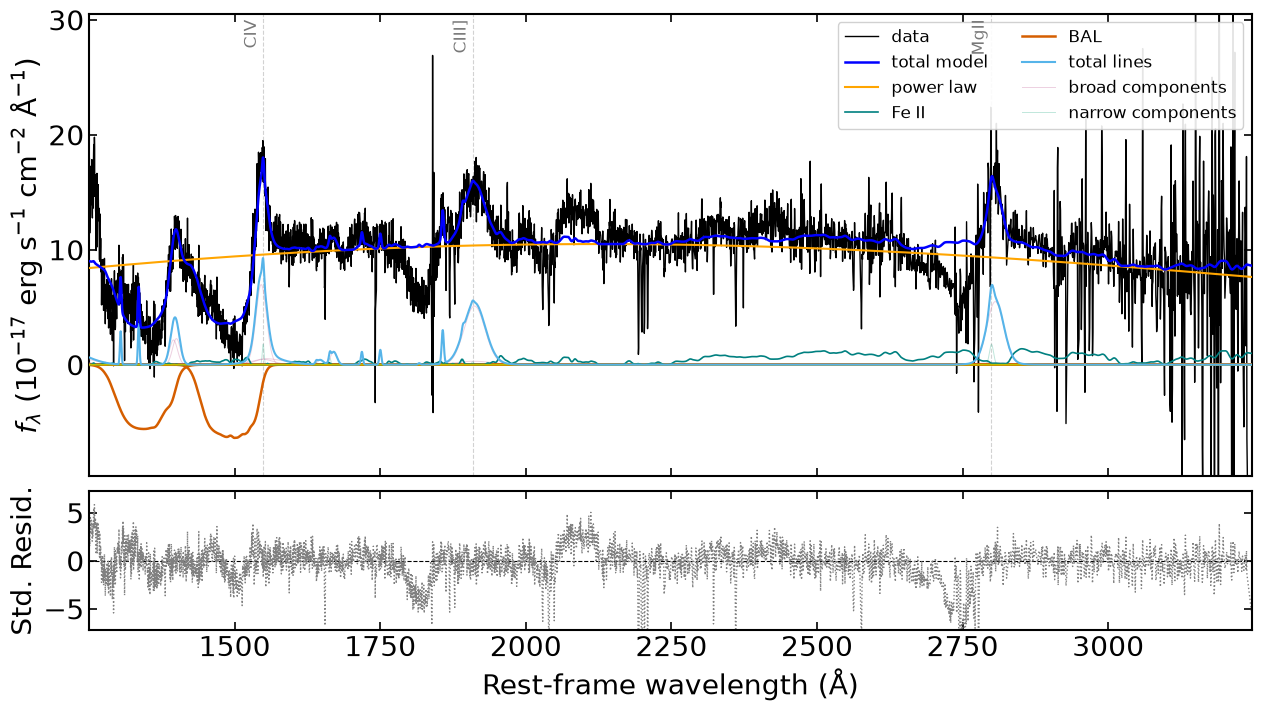

In [3]:
config = FitConfig(
    observation=Observation(object_id="7850-56956-0924", redshift=z, ra=ra, dec=dec),
    spectroscopy=SpectroscopyData(wave_obs=wave, fluxes=flux, errors=err, resolving_power=resolving_power),
    preprocessing=PreprocessingConfig(wave_range=(1250.0, 32000.0)),
    continuum=ContinuumConfig(fit_feii=True, fit_balmer_continuum=False, fit_reddening=True),
    bal=BALConfig(enabled=True),
    host=HostConfig(enabled=False),
    lines=LineConfig(enabled=True),
    inference=InferenceConfig(method="optax", map_steps=600),
    output=OutputConfig(save_result=False, save_fig=False, show_plot=True),
)

fitter = JAXQSOFit(config)
result = fitter.fit(verbose=False)

## 3. The C IV trough

Each fitted trough is stored in `fitter.custom_components` (here `bal_civ`), and the trough parameters in `result.median`. `balnicity_index` returns a BALnicity-style index (km/s) from the fitted C IV trough, with its uncertainty.

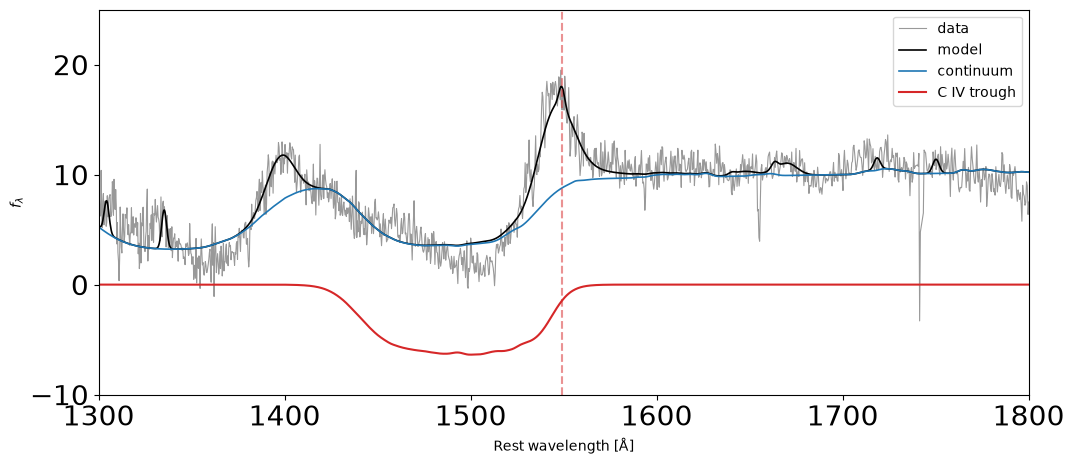

In [4]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(fitter.wave, fitter.flux, color="0.6", lw=0.8, label="data")
ax.plot(fitter.wave, fitter.model_total, color="k", lw=1.2, label="model")
ax.plot(fitter.wave, fitter.f_conti_model, color="tab:blue", lw=1.2, label="continuum")
ax.plot(fitter.wave, fitter.custom_components["bal_civ"], color="tab:red", lw=1.5, label="C IV trough")
ax.axvline(1549.06, color="tab:red", ls="--", alpha=0.5)
ax.set_xlim(1300.0, 1800.0)
ax.set_ylim(-10.0, 25.0)
ax.set_xlabel("Rest wavelength [Å]")
ax.set_ylabel(r"$f_\lambda$")
ax.legend();

In [5]:
for key, value in result.median.items():
    if key.startswith("custom_bal"):
        print(f"{key:28s} {value:.3f}")
balnicity, balnicity_err = fitter.balnicity_index()
print(f"BALnicity index: {balnicity:.0f} ± {balnicity_err:.0f} km/s")

custom_bal_tau_peak          2.757
custom_bal_covering          0.677
custom_bal_v_out             11882.811
custom_bal_fwhm_kms          14933.960
custom_bal_nv_shape_power    3.099
custom_bal_siiv_shape_power  2.218
custom_bal_civ_shape_power   2.703
BALnicity index: 10333 ± 0 km/s
